# Section 4.2 — Uniform-mixture simulation
Run cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

## e-Holm and p-Holm

In [2]:
def e_holm(evals):
  if len(evals) == 0:
    return []

  pairs = sorted(enumerate(evals), key=lambda t: t[1], reverse = True)
  orig_idx = [i for i, _ in pairs]
  e_sorted = [x for _, x in pairs]
  n = len(e_sorted)

  e_adjusted = np.zeros(n)
  e_adjusted[n-1] = e_sorted[n-1]

  k = 1
  E_k = e_sorted[n-k]
  e_adj = float('inf')
  for r in range(1, n):
    i = n - 1 - r
    e = e_sorted[i]
    e_adj = e / (k+1) + E_k * k / (k+1)
    while(e_adj > e_sorted[n - k - 1]):
      E_k = E_k * k / (k+1) + e_sorted[n - k - 1] / (k+1)
      k = k + 1
      e_adj = e / (k+1) + E_k * k / (k+1)
      if k == n:
        break
    e_adjusted[i] = e_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = e_adjusted[sorted_pos]
  return adjusted

In [3]:
# Compute Holm-adjusted p-values.
def p_holm(pvals):
  if len(pvals) == 0:
    return []

  pairs = sorted(enumerate(pvals), key=lambda t: t[1])
  orig_idx = [i for i, _ in pairs]
  p_sorted = [x for _, x in pairs]
  n = len(p_sorted)

  p_adjusted = np.zeros(n)
  p_adj = p_sorted[0] * n
  p_adjusted[0] = p_adj

  for i in range(1,n):
    p_i = p_sorted[i] * (n - i)
    if p_i > p_adj:
      p_adj = p_i
    p_adjusted[i] = p_adj

  adjusted = np.zeros(n)
  for sorted_pos, i in enumerate(orig_idx):
    adjusted[i] = p_adjusted[sorted_pos]
  return adjusted

## Simulation — Figure 2

In [4]:
n_1s = range(5, 11)
cs = [0.005, 0.01, 0.025]
n = 10
alpha = 0.05
pi = 0.01
n_iter = 1000

def generate_vals(n, n_1, pi, c):
  n_0 = n - n_1
  indicators = np.random.binomial(1, 1 - pi, size=n_1)
  nonnulls = np.array([1 - np.random.uniform() * (1 - (1 - c) * indicators[i]) for i in range(n_1)])
  return np.concatenate([nonnulls, np.random.uniform(size=n_0)])

def compute_evals(data, c):
  return np.array([1 / c if x > 1 - c else 0 for x in data])

e_fwers = np.zeros((len(n_1s), len(cs)))
p_fwers = np.zeros((len(n_1s), len(cs)))
ep_fwers = np.zeros((len(n_1s), len(cs)))
e_powers = np.zeros((len(n_1s), len(cs)))
p_powers = np.zeros((len(n_1s), len(cs)))
ep_powers = np.zeros((len(n_1s), len(cs)))

np.random.seed(0)
for iteration in tqdm(range(n_iter)):
  for i, n_1 in enumerate(n_1s):
    for j, c in enumerate(cs):
      data = generate_vals(n, n_1, pi, c)
      evals = compute_evals(data, c)
      pvals = 1 - data
      adj_evals = e_holm(evals)
      adj_pvals = p_holm(pvals)
      adj_epvals = p_holm(1 - (1-c) * c * evals)
      e_fwers[i, j] += any(adj_evals[n_1:] >= 1/alpha) / n_iter
      p_fwers[i, j] += any(adj_pvals[n_1:] <= alpha) / n_iter
      ep_fwers[i, j] += any(adj_epvals[n_1:] <= alpha) / n_iter
      e_powers[i, j] += np.sum(adj_evals[:n_1] >= 1/alpha) / (n_1 * n_iter)
      p_powers[i, j] += np.sum(adj_pvals[:n_1] <= alpha) / (n_1 * n_iter)
      ep_powers[i, j] += np.sum(adj_epvals[:n_1] <= alpha) / (n_1 * n_iter)

  0%|          | 0/1000 [00:00<?, ?it/s]

### Figure 2 — FWER

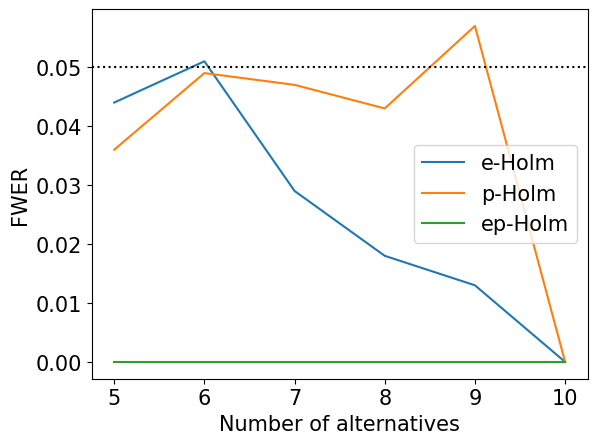

In [5]:
plt.rcParams.update({'font.size': 15})
j = 1

plt.plot(n_1s, e_fwers[:,j], label = 'e-Holm')
plt.plot(n_1s, p_fwers[:,j], label = 'p-Holm')
plt.plot(n_1s, ep_fwers[:,j], label = 'ep-Holm')
plt.axhline(y=alpha, color = 'black', linestyle = 'dotted')
plt.legend()
plt.xlabel('Number of alternatives')
plt.ylabel('FWER')
plt.show()

### Figure 2 — Power

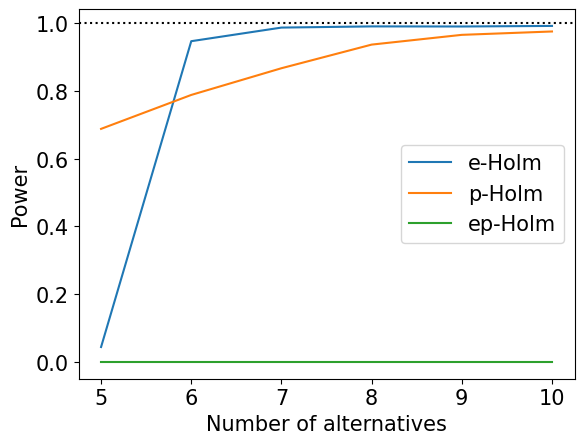

In [6]:
plt.rcParams.update({'font.size': 15})
j = 1

plt.plot(n_1s, e_powers[:,j], label = 'e-Holm')
plt.plot(n_1s, p_powers[:,j], label = 'p-Holm')
plt.plot(n_1s, ep_powers[:,j], label = 'ep-Holm')


plt.axhline(y=1, color = 'black', linestyle = 'dotted')
plt.legend()
plt.xlabel('Number of alternatives')
plt.ylabel('Power')
plt.show()